In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from data import GDPHMM_OAR_V3
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED

In [4]:
dataset = build_dataset('test')

In [ ]:
baseline_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
fp16_train_pred = ModelResults('111-mixed-precision', 'ddpm-1000', 199, 'test', dataset)
bf16_train_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)
bf16_samp_pred = ModelResults('101-beamdiff', 'ddpm-1000-bf16-amp', 199, 'test', dataset)
fp16_samp_pred = ModelResults('101-beamdiff', 'ddpm-1000-fp16-amp', 199, 'test', dataset)
bf16_bf16_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000-bf16-amp', 199, 'test', dataset)
bf16_fp16_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000-fp16-amp', 199, 'test', dataset)

# Mixed Precision Training

In [6]:
training_comparison = ModelComparison(
  [baseline_pred, fp16_train_pred, bf16_train_pred],
  ['Baseline', 'FP16 AMP Training', 'BF16 AMP Training'],
)

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1129: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1129: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1129: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1129: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore 

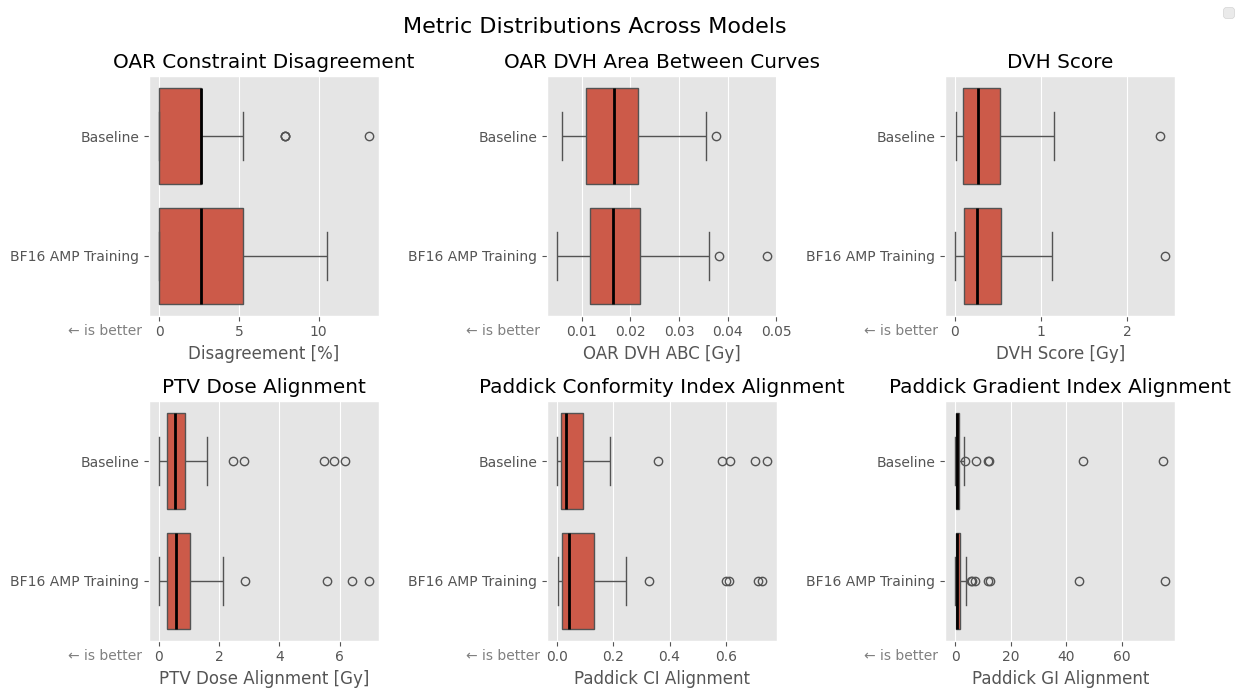

In [7]:
_ = (training_comparison - fp16_train_pred).plot_metric_distributions(METRICS_PRED, sort=False, outliers=True)

# Post-Training Quantization Sampling

In [8]:
sampling_comparison = ModelComparison(
  [baseline_pred, bf16_samp_pred, fp16_samp_pred],
  ['Baseline', 'bfloat16 Sampling', 'float16 Sampling']
)

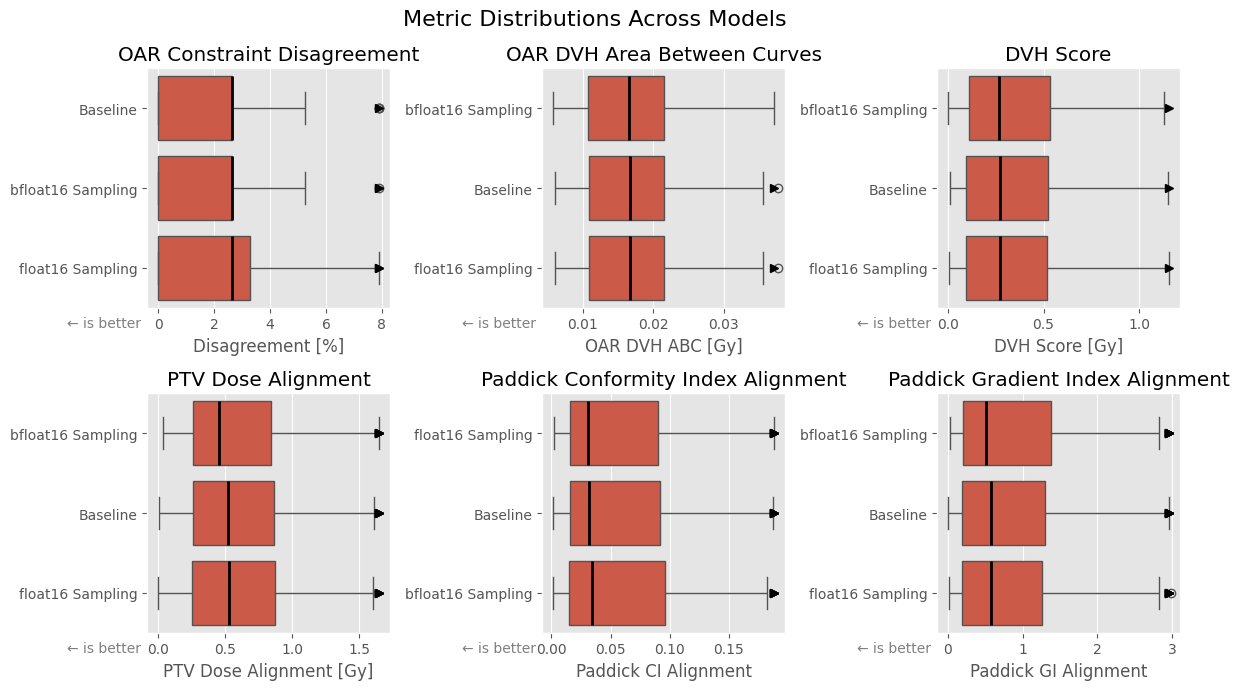

In [9]:
_ = sampling_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=False)

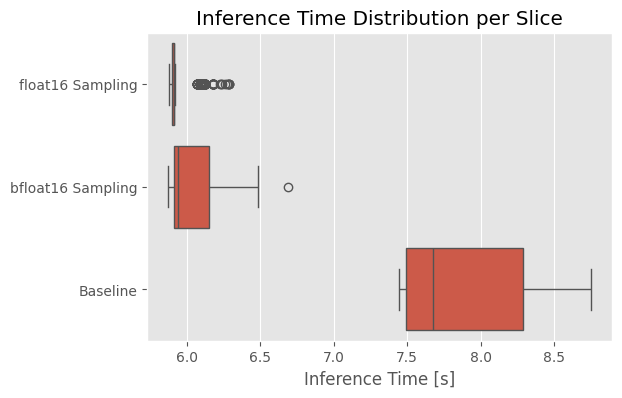

In [10]:
_ = sampling_comparison.plot_inference_times('slice', unit='seconds')

# AMP + Post-Training Quantization

In [11]:
bf16_train_comparison = ModelComparison(
  [bf16_train_pred, bf16_bf16_pred, bf16_fp16_pred],
  ['Baseline', 'bfloat16 Sampling', 'float16 Sampling']
)

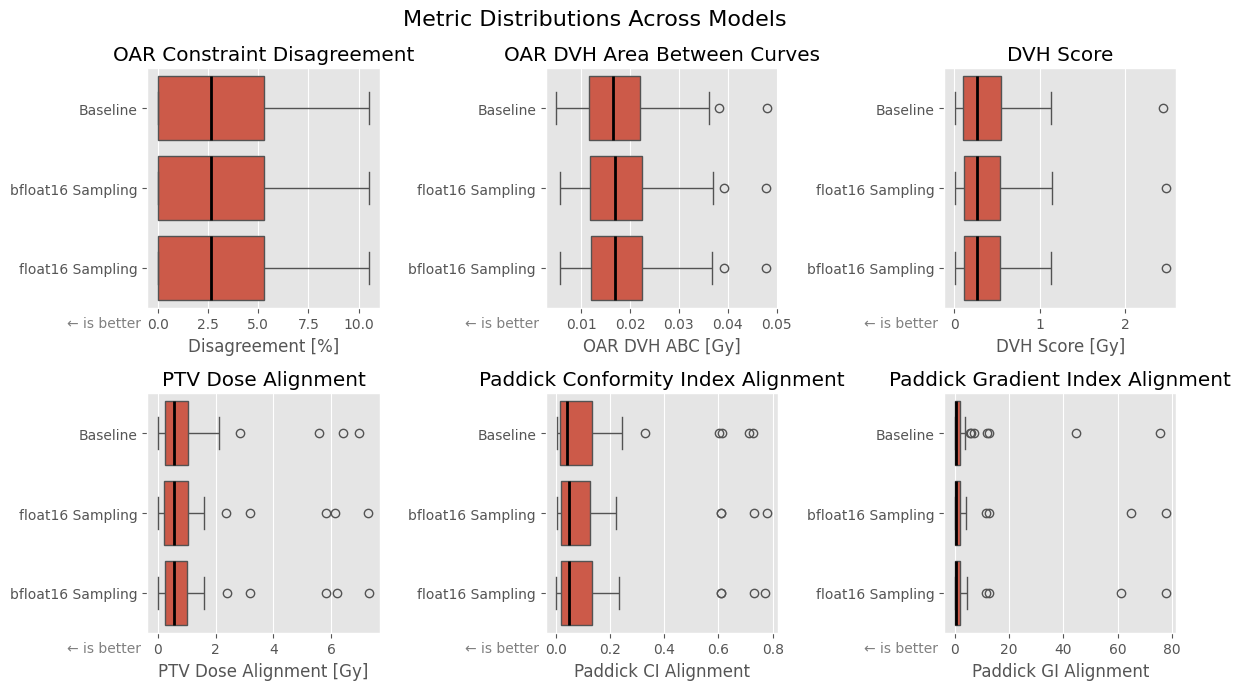

In [12]:
_ = bf16_train_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=True)

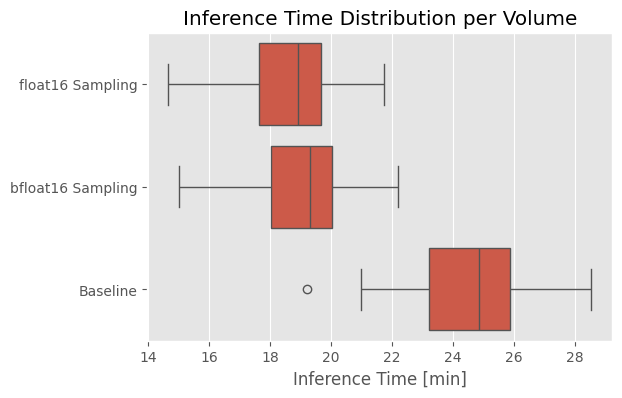

In [13]:
_ = sampling_comparison.plot_inference_times()

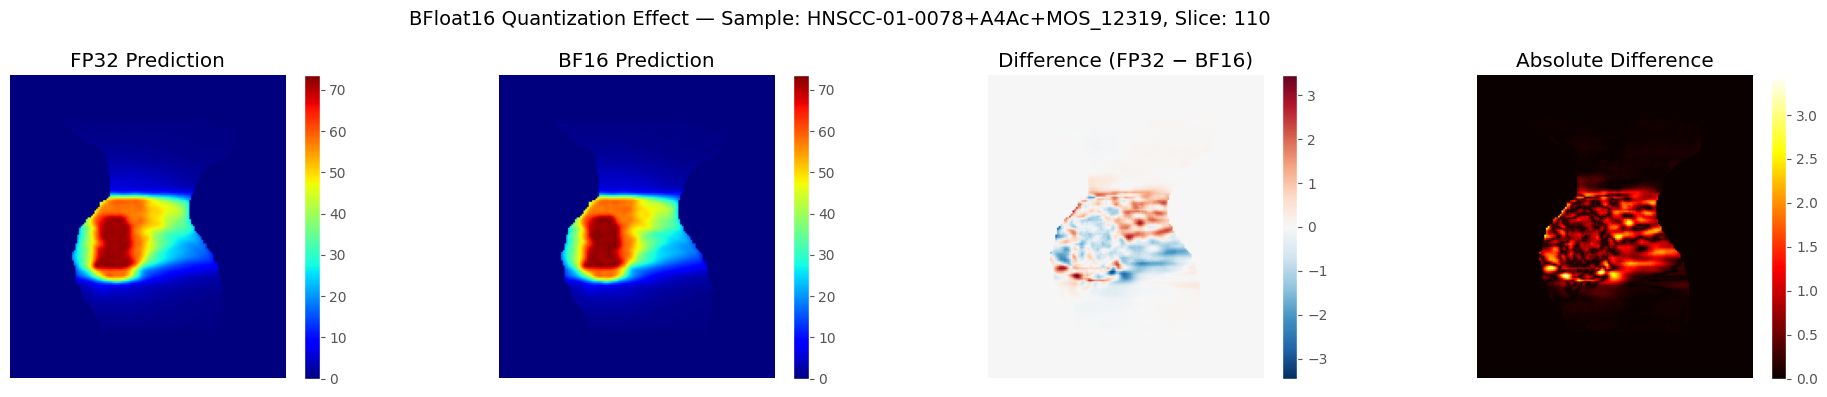

Max absolute difference: 14.841451
Mean absolute difference: 0.038901
RMSE: 0.218312


In [14]:
import numpy as np

sample_name = 'HNSCC-01-0078+A4Ac+MOS_12319'

baseline_sample = bf16_train_pred.for_sample(sample_name)
bf16_sample = bf16_bf16_pred.for_sample(sample_name)

_, orig_dose = baseline_sample.load_orig_volume()
fp32_pred = baseline_sample.load_pred_volume()
bf16_pred = bf16_sample.load_pred_volume()

diff = fp32_pred - bf16_pred

# Pick the central axial slice
z = 110

vmin, vmax = 0, max(fp32_pred[:, :, z].max(), bf16_pred[:, :, z].max())

fig, axes = plt.subplots(1, 4, figsize=(20, 4))

im0 = axes[0].imshow(fp32_pred[:, :, z], cmap='jet', vmin=vmin, vmax=vmax)
axes[0].set_title('FP32 Prediction')
axes[0].axis('off')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(bf16_pred[:, :, z], cmap='jet', vmin=vmin, vmax=vmax)
axes[1].set_title('BF16 Prediction')
axes[1].axis('off')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

abs_max = np.abs(diff[:, :, z]).max()
im2 = axes[2].imshow(diff[:, :, z], cmap='RdBu_r', vmin=-abs_max, vmax=abs_max)
axes[2].set_title('Difference (FP32 − BF16)')
axes[2].axis('off')
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

im3 = axes[3].imshow(np.abs(diff[:, :, z]), cmap='hot')
axes[3].set_title('Absolute Difference')
axes[3].axis('off')
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

fig.suptitle(f'BFloat16 Quantization Effect — Sample: {sample_name}, Slice: {z}', fontsize=14)
fig.tight_layout()
plt.show()

print(f'Max absolute difference: {np.abs(diff).max():.6f}')
print(f'Mean absolute difference: {np.abs(diff).mean():.6f}')
print(f'RMSE: {np.sqrt(np.mean(diff**2)):.6f}')

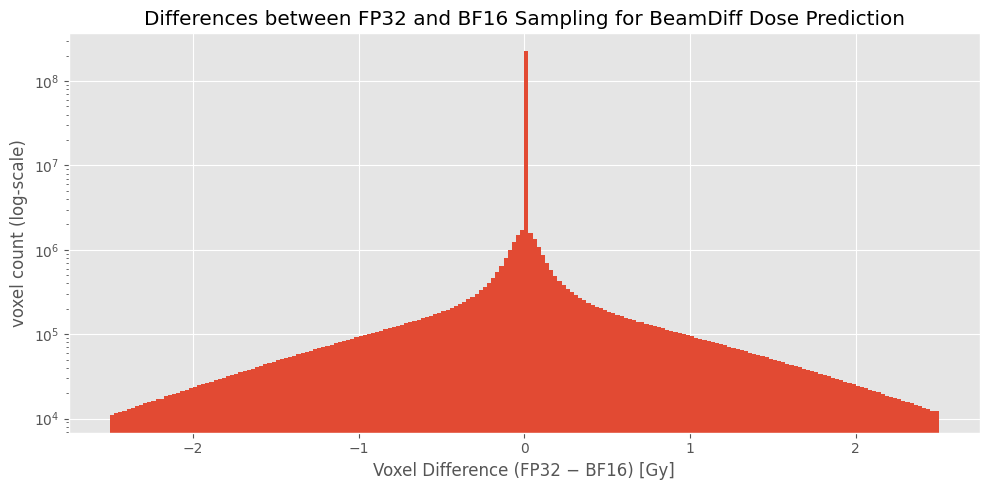

Total voxels: 256,171,520
Mean difference: 0.001697
Std difference: 0.298306
Max absolute difference: 26.636578


In [16]:
n_bins = 200
bin_edges = np.linspace(-2.5, 2.5, n_bins + 1)
counts = np.zeros(n_bins, dtype=np.int64)

stats_sum = 0.0
stats_sq_sum = 0.0
stats_max = 0.0
stats_n = 0

for sample_file in bf16_train_pred.volume_metrics['file_name']:
    sample_name = sample_file.replace('.npz', '')
    fp32_vol = bf16_train_pred.for_sample(sample_name).load_pred_volume()
    bf16_vol = bf16_bf16_pred.for_sample(sample_name).load_pred_volume()
    diff = (fp32_vol - bf16_vol).ravel()

    counts += np.histogram(diff, bins=bin_edges)[0]
    stats_sum += diff.sum()
    stats_sq_sum += (diff ** 2).sum()
    stats_max = max(stats_max, np.abs(diff).max())
    stats_n += len(diff)

mean_diff = stats_sum / stats_n
std_diff = np.sqrt(stats_sq_sum / stats_n - mean_diff ** 2)

fig, ax = plt.subplots(figsize=(10, 5))
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
ax.bar(bin_centers, counts, width=bin_edges[1] - bin_edges[0], edgecolor='none')
ax.set_yscale('log')
ax.set_xlabel('Voxel Difference (FP32 − BF16) [Gy]')
ax.set_ylabel('voxel count (log-scale)')
ax.set_title('Differences between FP32 and BF16 Sampling for BeamDiff Dose Prediction')
fig.tight_layout()
plt.show()

print(f'Total voxels: {stats_n:,}')
print(f'Mean difference: {mean_diff:.6f}')
print(f'Std difference: {std_diff:.6f}')
print(f'Max absolute difference: {stats_max:.6f}')